# 01 · Profiling và làm sạch dữ liệu (Tuần 4)
Đề tài nhánh Lập trình AI: **mô hình gợi ý sản phẩm**.

Notebook chạy lại được từ đầu đến cuối. Dữ liệu nằm ở schema `masked_data` (đổi bằng biến `PGSCHEMA` nếu server khác). Cấu hình kết nối đọc từ biến môi trường hoặc file `.env`
(đã thêm `.env` và `data/` vào `.gitignore`), **không ghi mật khẩu vào notebook**:

```
PGHOST=...
PGPORT=...
PGDATABASE=...
PGUSER=...
PGPASSWORD=...
PGSCHEMA=masked_data
```

**Quy ước hóa đơn hợp lệ:** `is_revenue_valid::text::boolean IS TRUE AND is_cancelled::text::boolean IS NOT TRUE`.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Nếu repo của bạn đã có src/db.py (Tuần 1) thì có thể thay 3 dòng dưới bằng hàm của nó.
URL = "postgresql+psycopg2://{u}:{p}@{h}:{port}/{db}".format(
    u=os.environ["PGUSER"], p=os.environ["PGPASSWORD"], h=os.environ["PGHOST"],
    port=os.environ.get("PGPORT", "5432"), db=os.environ["PGDATABASE"])
SCHEMA = os.environ.get("PGSCHEMA", "masked_data")   # schema chứa dữ liệu trên server của lớp
engine = create_engine(URL, connect_args={"options": f"-csearch_path={SCHEMA},public"})

DATA = Path("data"); DATA.mkdir(exist_ok=True)
REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)

def q(sql: str) -> pd.DataFrame:
    with engine.connect() as con:
        return pd.read_sql(text(sql), con)

VALID = "i.is_revenue_valid::text::boolean IS TRUE AND i.is_cancelled::text::boolean IS NOT TRUE"
q("SELECT current_database() AS db, now() AS luc")

,db,luc
0,dev,2026-10-25 16:54:44.922761+00:00


## 1. Data profiling
Với mỗi bảng: kiểu dữ liệu, % thiếu (NULL hoặc chuỗi rỗng), số giá trị khác nhau, min/max (so sánh dạng chữ).
Bảng này là bước tham khảo; **trong báo cáo hãy tự tóm tắt** những cột đáng chú ý, không dán nguyên bảng.

In [2]:
TABLES = ["invoice", "invoice_detail", "sku", "item", "branch", "customer", "customer_points"]

def profile_table(table: str) -> pd.DataFrame:
    cols = q(f"""SELECT column_name, data_type FROM information_schema.columns
               WHERE table_schema = '{SCHEMA}' AND table_name = '{table}'
               ORDER BY ordinal_position""")
    if cols.empty:
        raise RuntimeError(f"Không thấy bảng '{table}' trong schema '{SCHEMA}' - kiểm tra PGSCHEMA hoặc quyền truy cập")
    parts = []
    for c in cols.column_name:
        parts.append(f"""SELECT '{c}' AS cot,
              COUNT(*) AS so_dong,
              COUNT(*) FILTER (WHERE "{c}" IS NULL OR TRIM("{c}"::text) = '') AS so_thieu,
              COUNT(DISTINCT "{c}") AS so_gia_tri_khac_nhau,
              MIN("{c}"::text) AS min_text, MAX("{c}"::text) AS max_text
            FROM {table}""")
    prof = q(" UNION ALL ".join(parts))
    prof = cols.rename(columns={"column_name": "cot"}).merge(prof, on="cot")
    prof["pct_thieu"] = 100 * prof.so_thieu / prof.so_dong
    prof.insert(0, "bang", table)
    return prof

profiles = pd.concat([profile_table(t) for t in TABLES], ignore_index=True)
profiles.to_csv(REPORTS / "profiling_all_tables.csv", index=False)
profiles.groupby("bang").agg(so_cot=("cot", "count"), so_dong=("so_dong", "max"))

,so_cot,so_dong
bang,,
branch,13,121
customer,15,495263
customer_points,11,270300
invoice,31,251945
invoice_detail,11,730888
item,33,15606
sku,9,36109


In [3]:
# Cột thiếu nhiều (> 20%): ứng viên bị loại khỏi mô hình
profiles.loc[profiles.pct_thieu > 20, ["bang", "cot", "data_type", "so_thieu", "pct_thieu"]] \
        .sort_values("pct_thieu", ascending=False)

,bang,cot,data_type,so_thieu,pct_thieu
68,item,weight,text,15606,100.00
49,sku,source_updated_at,text,36109,100.00
81,item,lated_date,text,15606,100.00
82,item,source_updated_at,text,15606,100.00
88,branch,khu_vuc,text,121,100.00
91,branch,open_date,text,121,100.00
78,item,characters,text,15606,100.00
74,item,unit_cost,text,15606,100.00
121,customer_points,updated_at,text,270300,100.00
110,customer,updated_at,text,495263,100.00


In [4]:
# Cột đang ở kiểu text nhưng thực chất là ngày/số -> cần ép kiểu (ghi lại để dùng ở Tuần 5)
profiles[(profiles.data_type.isin(["text", "character varying"])) &
         (profiles.cot.str.contains("date|time|amount|quantity|price|point", case=False))] \
        [["bang", "cot", "data_type", "min_text", "max_text"]]

,bang,cot,data_type,min_text,max_text
3,invoice,invoice_date,text,2025-01-01 08:58:07.000,2025-12-30 22:00:00.000
4,invoice,invoice_time,text,2025-01-01 08:58:07.000,2025-12-30 22:00:00.000
7,invoice,total_item_amount,text,0.0,999680.0
8,invoice,total_amount,text,0.0,999860.0
9,invoice,actual_amount,text,0.0,999800.0
10,invoice,discount_amount,text,0.0,99950.0
11,invoice,vat_amount,text,0.0,0.0
12,invoice,cost_amount,text,0.0,0.0
13,invoice,cash_amount,text,0.0,999860.0
14,invoice,card_amount,text,0.0,999800.0


## 2. Checklist chất lượng dữ liệu (9 điểm bắt buộc)
Mỗi truy vấn trả một dòng số liệu. Sau khi chạy, điền cột *Ảnh hưởng* và *Xử lý* trong `reports/checklist_chat_luong.csv`
(hoặc trong báo cáo, mục 4).

In [5]:
CHECKS = {
"1. Ngày giờ / ngoài năm 2025": """
    SELECT MIN(invoice_date::timestamp) AS ngay_som_nhat, MAX(invoice_date::timestamp) AS ngay_muon_nhat,
           COUNT(*) FILTER (WHERE invoice_date::timestamp <  DATE '2025-01-01'
                               OR invoice_date::timestamp >= DATE '2026-01-01') AS so_hd_ngoai_2025
    FROM invoice""",
"2. Loại chứng từ & hóa đơn âm": """
    SELECT COUNT(DISTINCT invoice_type) AS so_loai_chung_tu,
           COUNT(*) FILTER (WHERE actual_amount::numeric < 0) AS so_hd_am,
           SUM(actual_amount::numeric) FILTER (WHERE actual_amount::numeric < 0) AS tong_tien_am
    FROM invoice""",
"3. Hóa đơn hủy / thất bại / không hợp lệ": """
    SELECT COUNT(*) FILTER (WHERE is_cancelled::text::boolean IS TRUE) AS huy,
           COUNT(*) FILTER (WHERE is_failed::text::boolean IS TRUE) AS that_bai,
           COUNT(*) FILTER (WHERE is_revenue_valid::text::boolean IS NOT TRUE) AS khong_tinh_doanh_thu,
           COUNT(*) FILTER (WHERE is_revenue_valid::text::boolean IS TRUE AND is_cancelled::text::boolean IS TRUE) AS vua_hop_le_vua_huy
    FROM invoice""",
"4. Ngoại lai": """
    SELECT PERCENTILE_CONT(0.99) WITHIN GROUP (ORDER BY actual_amount::numeric) AS p99_actual_amount,
           MAX(actual_amount::numeric) AS max_actual_amount,
           COUNT(*) FILTER (WHERE discount_amount::numeric > total_item_amount::numeric) AS giam_gia_lon_hon_tien_hang
    FROM invoice""",
"4b. Ngoại lai: số lượng dòng": """
    SELECT MAX(quantity::numeric) AS max_quantity, MIN(quantity::numeric) AS min_quantity,
           PERCENTILE_CONT(0.999) WITHIN GROUP (ORDER BY quantity::numeric) AS p999_quantity
    FROM invoice_detail""",
"5a. Mã hàng không khớp sku": """
    SELECT COUNT(DISTINCT d.item_code) AS so_ma, COUNT(*) AS so_dong
    FROM invoice_detail d LEFT JOIN sku s ON s.sku = d.item_code
    WHERE s.sku IS NULL""",
"5b. Mã cửa hàng không khớp branch": """
    SELECT COUNT(DISTINCT i.branch_code) AS so_ma, COUNT(*) AS so_hd
    FROM invoice i LEFT JOIN branch b ON b.location_code = i.branch_code
    WHERE b.location_code IS NULL""",
"5c. Sku không có item mẹ": """
    SELECT COUNT(*) AS so_sku
    FROM sku s LEFT JOIN item it ON it.item = s.item_no
    WHERE it.item IS NULL""",
"5d. Tổng chi tiết lệch tổng hóa đơn": """
    WITH ds AS (SELECT invoice_id, SUM(total_amount::numeric) AS t FROM invoice_detail GROUP BY invoice_id)
    SELECT COUNT(*) FILTER (WHERE ds.t IS NULL) AS hd_khong_co_chi_tiet,
           COUNT(*) FILTER (WHERE ABS(ds.t - i.total_amount::numeric) > 1) AS hd_lech_hon_1_dong,
           MAX(ABS(ds.t - i.total_amount::numeric)) AS lech_lon_nhat
    FROM invoice i LEFT JOIN ds ON ds.invoice_id = i.invoice_id""",
"6. Mã có ký tự lạ": """
    SELECT (SELECT COUNT(*) FROM invoice_detail WHERE item_code <> TRIM(item_code)
              OR item_code ~ '[^A-Za-z0-9._-]') AS item_code_la,
           (SELECT COUNT(*) FROM sku WHERE sku <> TRIM(sku) OR sku ~ '[^A-Za-z0-9._-]') AS sku_la,
           (SELECT COUNT(*) FROM item WHERE item <> TRIM(item) OR item ~ '[^A-Za-z0-9._-]') AS item_la""",
"7. Cột thiếu dữ liệu": """
    SELECT (SELECT 100.0 * COUNT(*) FILTER (WHERE NULLIF(TRIM(birthday::text),'') IS NULL) / COUNT(*) FROM customer) AS pct_thieu_birthday,
           (SELECT 100.0 * COUNT(*) FILTER (WHERE NULLIF(TRIM(province::text),'') IS NULL) / COUNT(*) FROM customer) AS pct_thieu_province,
           (SELECT 100.0 * COUNT(*) FILTER (WHERE NULLIF(TRIM(plc_price::text),'') IS NULL) / COUNT(*) FROM item) AS pct_thieu_plc_price,
           (SELECT 100.0 * COUNT(*) FILTER (WHERE NULLIF(TRIM(cost_amount::text),'') IS NULL
                                              OR cost_amount::numeric = 0) / COUNT(*) FROM invoice) AS pct_thieu_hoac_0_cost_amount""",
"8a. Trùng detail_key": """
    SELECT COUNT(*) - COUNT(DISTINCT detail_key) AS dong_trung_detail_key FROM invoice_detail""",
"8b. Dòng chi tiết nghi trùng": """
    SELECT COALESCE(SUM(n - 1), 0) AS dong_nghi_trung FROM (
      SELECT COUNT(*) AS n FROM invoice_detail
      GROUP BY invoice_id, item_code, quantity, unit_price, total_amount HAVING COUNT(*) > 1) x""",
"8c. Trùng customer_id": """
    SELECT COUNT(*) - COUNT(DISTINCT customer_id) AS khach_trung FROM customer""",
"9a. Hóa đơn thiếu kênh": """
    SELECT COUNT(*) AS so_hd_thieu_kenh FROM invoice WHERE NULLIF(TRIM(sale_channel::text), '') IS NULL""",
"9b. Doanh thu ở cửa hàng đã đóng": """
    SELECT COUNT(*) AS so_hd, SUM(i.actual_amount::numeric) AS doanh_thu
    FROM invoice i JOIN branch b ON b.location_code = i.branch_code
    WHERE b.status ILIKE '%closed%'""",
}

rows = []
for name, sql in CHECKS.items():
    r = q(sql).iloc[0]
    rows.append({"kiem_tra": name, "ket_qua": "; ".join(f"{k}={v:,.2f}" if isinstance(v, (float, np.floating))
                                                      else f"{k}={v}" for k, v in r.items()),
                 "anh_huong": "", "cach_xu_ly": ""})
checklist = pd.DataFrame(rows)
checklist.to_csv(REPORTS / "checklist_chat_luong.csv", index=False)
checklist[["kiem_tra", "ket_qua"]]

,kiem_tra,ket_qua
0,1. Ngày giờ / ngoài năm 2025,ngay_som_nhat=2025-01-01 08:58:07; ngay_muon_n...
1,2. Loại chứng từ & hóa đơn âm,"so_loai_chung_tu=4.00; so_hd_am=8,206.00; tong..."
2,3. Hóa đơn hủy / thất bại / không hợp lệ,huy=204; that_bai=34; khong_tinh_doanh_thu=238...
3,4. Ngoại lai,"p99_actual_amount=2,607,168.00; max_actual_amo..."
4,4b. Ngoại lai: số lượng dòng,"max_quantity=2,000.00; min_quantity=-24.00; p9..."
5,5a. Mã hàng không khớp sku,so_ma=4; so_dong=1337
6,5b. Mã cửa hàng không khớp branch,so_ma=1; so_hd=652
7,5c. Sku không có item mẹ,so_sku=0
8,5d. Tổng chi tiết lệch tổng hóa đơn,hd_khong_co_chi_tiet=1.00; hd_lech_hon_1_dong=...
9,6. Mã có ký tự lạ,item_code_la=3; sku_la=36; item_la=4


## 3. Làm sạch và dựng bảng tương tác cho mô hình gợi ý
Quyết định làm sạch (ghi vào bảng ở cuối mục này):

1. Chỉ lấy hóa đơn hợp lệ.
2. Chỉ lấy dòng bán (`quantity > 0`); dòng trả hàng không phải sở thích mua.
3. Chuẩn hóa mã hàng (`TRIM`, `UPPER`) rồi nối `sku`; dòng không nối được bị loại (không có item để gợi ý).
4. Chỉ giữ khách có `customer_id` (khách vãng lai không cá nhân hóa được).
5. Chỉ giữ dữ liệu năm 2025.

In [6]:
steps = q(f"""
    WITH base AS (
      SELECT d.quantity::numeric, i.invoice_date::timestamp AS ts, NULLIF(TRIM(i.customer_id), '') AS cid,
             (i.is_revenue_valid::text::boolean IS TRUE AND i.is_cancelled::text::boolean IS NOT TRUE) AS hop_le,
             (s.sku IS NOT NULL) AS co_sku
      FROM invoice_detail d
      JOIN invoice i ON i.invoice_id = d.invoice_id
      LEFT JOIN sku s ON UPPER(TRIM(s.sku)) = UPPER(TRIM(d.item_code))
    )
    SELECT COUNT(*)                                                                  AS tong_dong,
           COUNT(*) FILTER (WHERE hop_le)                                            AS sau_hoa_don_hop_le,
           COUNT(*) FILTER (WHERE hop_le AND quantity > 0)                           AS sau_dong_ban,
           COUNT(*) FILTER (WHERE hop_le AND quantity > 0 AND co_sku)                AS sau_khop_sku,
           COUNT(*) FILTER (WHERE hop_le AND quantity > 0 AND co_sku AND cid IS NOT NULL) AS sau_co_khach,
           COUNT(*) FILTER (WHERE hop_le AND quantity > 0 AND co_sku AND cid IS NOT NULL
                              AND ts >= DATE '2025-01-01' AND ts < DATE '2026-01-01')     AS sau_nam_2025
    FROM base""").iloc[0]

cleaning_log = pd.DataFrame({
    "buoc_lam_sach": ["Hóa đơn hợp lệ (không hủy, tính doanh thu)", "Chỉ dòng bán (quantity > 0)",
                      "Nối được sku (sau TRIM/UPPER)", "Có customer_id", "Trong năm 2025"],
    "so_dong_con_lai": steps.iloc[1:].astype(int).values,
})
cleaning_log["so_dong_bi_loai"] = steps.iloc[0:5].astype(int).values - cleaning_log.so_dong_con_lai.values
cleaning_log["ly_do"] = ["Hóa đơn hủy/không hợp lệ không phản ánh nhu cầu thật",
                         "Dòng trả hàng không phải tín hiệu mua", "Không có item để gợi ý (túi, phí, quà...)",
                         "Khách vãng lai không cá nhân hóa được", "Phạm vi phân tích"]
cleaning_log.to_csv(REPORTS / "bang_quyet_dinh_lam_sach.csv", index=False)
print("Tổng số dòng chi tiết ban đầu:", int(steps.tong_dong))
cleaning_log

Tổng số dòng chi tiết ban đầu: 730888


,buoc_lam_sach,so_dong_con_lai,so_dong_bi_loai,ly_do
0,"Hóa đơn hợp lệ (không hủy, tính doanh thu)",729654,1234,Hóa đơn hủy/không hợp lệ không phản ánh nhu cầ...
1,Chỉ dòng bán (quantity > 0),712432,17222,Dòng trả hàng không phải tín hiệu mua
2,Nối được sku (sau TRIM/UPPER),712429,3,"Không có item để gợi ý (túi, phí, quà...)"
3,Có customer_id,373916,338513,Khách vãng lai không cá nhân hóa được
4,Trong năm 2025,373916,0,Phạm vi phân tích


In [8]:
interactions = q(f"""
    SELECT NULLIF(TRIM(i.customer_id), '')        AS customer_id,
           s.item_no                              AS item,
           i.invoice_date::timestamp::date        AS ngay,
           COUNT(DISTINCT i.invoice_id)           AS so_hoa_don,
           SUM(d.quantity::numeric)                        AS so_luong
    FROM invoice_detail d
    JOIN invoice i ON i.invoice_id = d.invoice_id
    JOIN sku s     ON UPPER(TRIM(s.sku)) = UPPER(TRIM(d.item_code))
    WHERE {VALID}
      AND d.quantity::numeric > 0
      AND NULLIF(TRIM(i.customer_id), '') IS NOT NULL
      AND i.invoice_date::timestamp >= DATE '2025-01-01'
      AND i.invoice_date::timestamp <  DATE '2026-01-01'
    GROUP BY 1, 2, 3""")
interactions["ngay"] = pd.to_datetime(interactions["ngay"])
interactions["so_luong"] = interactions["so_luong"].astype(float)

items = q("""SELECT item, group_cat, gender, season, licenses, product_type FROM item""")
items["item"] = items["item"].astype(str)
interactions["item"] = interactions["item"].astype(str)

interactions.to_csv(DATA / "interactions.csv", index=False, encoding="utf-8-sig")
items.to_csv(DATA / "items.csv", index=False, encoding="utf-8-sig")
print(interactions.shape, items.shape)
interactions.head()

(350663, 5) (15606, 6)


,customer_id,item,ngay,so_hoa_don,so_luong
0,C_0000781213921587,20001000,2025-01-26,1,1.00
1,C_0000781213921587,33036,2025-01-26,1,1.00
2,C_0000781213921587,55001924,2025-01-26,1,1.00
3,C_00009ad00041e98b,20001000,2025-01-19,1,1.00
4,C_00009ad00041e98b,33038,2025-01-19,1,1.00


## 4. Độ khả thi của bài toán gợi ý
Các con số này quyết định mô hình nào dùng được. Điền vào mục 4 và mục 7 của báo cáo.

In [9]:
n_users = interactions.customer_id.nunique()
n_items = interactions.item.nunique()
n_inter = interactions[["customer_id", "item"]].drop_duplicates().shape[0]

days_per_user = interactions.groupby("customer_id").ngay.nunique()
inv_total = q(f"SELECT COUNT(*) AS n, COUNT(*) FILTER (WHERE NULLIF(TRIM(i.customer_id),'') IS NOT NULL) AS co_khach, "
              f"SUM(i.actual_amount::numeric) AS doanh_thu_tong, "
              f"SUM(i.actual_amount::numeric) FILTER (WHERE NULLIF(TRIM(i.customer_id),'') IS NOT NULL) AS doanh_thu_co_khach "
              f"FROM invoice i WHERE {VALID}").iloc[0]

summary = pd.Series({
    "so_khach": n_users, "so_item": n_items, "so_cap_khach_item": n_inter,
    "do_thua_pct": 100 * (1 - n_inter / (n_users * n_items)),
    "so_item_tb_moi_khach": n_inter / n_users,
    "pct_khach_mua_tu_2_ngay": 100 * (days_per_user >= 2).mean(),
    "pct_hoa_don_co_customer_id": 100 * inv_total.co_khach / inv_total.n,
    "pct_doanh_thu_co_customer_id": 100 * inv_total.doanh_thu_co_khach / inv_total.doanh_thu_tong,
})
summary

so_khach                        67,307.00
so_item                          2,832.00
so_cap_khach_item              334,831.00
do_thua_pct                         99.82
so_item_tb_moi_khach                 4.97
pct_khach_mua_tu_2_ngay             21.56
pct_hoa_don_co_customer_id          39.78
pct_doanh_thu_co_customer_id        54.07
dtype: float64

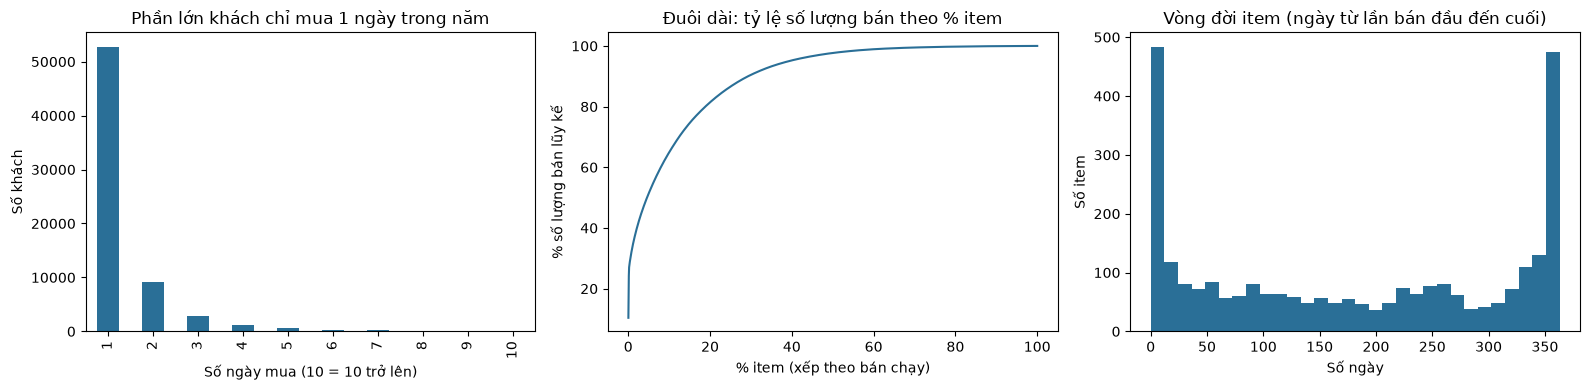

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

days_per_user.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax[0], color="#2a6f97")
ax[0].set_title("Phần lớn khách chỉ mua 1 ngày trong năm" if (days_per_user == 1).mean() > .5
                else "Phân bố số ngày mua của khách")
ax[0].set_xlabel("Số ngày mua (10 = 10 trở lên)"); ax[0].set_ylabel("Số khách")

pop = interactions.groupby("item").so_luong.sum().sort_values(ascending=False)
cum = pop.cumsum() / pop.sum()
ax[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color="#2a6f97")
ax[1].set_title("Đuôi dài: tỷ lệ số lượng bán theo % item")
ax[1].set_xlabel("% item (xếp theo bán chạy)"); ax[1].set_ylabel("% số lượng bán lũy kế")

life = interactions.groupby("item").ngay.agg(["min", "max"])
(life["max"] - life["min"]).dt.days.plot.hist(bins=30, ax=ax[2], color="#2a6f97")
ax[2].set_title("Vòng đời item (ngày từ lần bán đầu đến cuối)")
ax[2].set_xlabel("Số ngày"); ax[2].set_ylabel("Số item")
plt.tight_layout(); plt.savefig(REPORTS / "kha_thi_goi_y.png", dpi=150); plt.show()

## 5. Chia dữ liệu theo thời gian và baseline "bán chạy nhất"
- Train: trước 01/11/2025; Validation: tháng 11; Test: tháng 12 (khi test, train gồm cả tháng 11).
- Baseline: 10 item bán chạy nhất trong 30 ngày cuối của phần train, gợi ý giống nhau cho mọi khách.
- Metric: Recall@10 (số item đúng / số item khách thật sự mua trong cửa sổ), Hit Rate@10 (khách có ít nhất 1 item đúng).
- Ba nhóm khách trong cửa sổ đánh giá: có lịch sử (mua trước đó), khách mới (chưa từng mua). Chỉ nhóm "có lịch sử" mới là mục tiêu của mô hình cá nhân hóa.

In [11]:
K = 10
SPLITS = {
    "validation": ("2025-11-01", "2025-12-01"),   # train: < 11/01
    "test":       ("2025-12-01", "2026-01-01"),   # train: < 12/01
}

def popularity_topk(train: pd.DataFrame, days: int = 30, k: int = K) -> list:
    end = train.ngay.max()
    recent = train[train.ngay > end - pd.Timedelta(days=days)]
    return recent.groupby("item").so_luong.sum().nlargest(k).index.tolist()

def evaluate(recommend, name: str) -> pd.DataFrame:
    out = []
    for split, (start, stop) in SPLITS.items():
        train = interactions[interactions.ngay < start]
        window = interactions[(interactions.ngay >= start) & (interactions.ngay < stop)]
        truth = window.groupby("customer_id").item.apply(set)
        known = set(train.customer_id)
        rec = recommend(train)
        for group, mask in [("co_lich_su", truth.index.isin(known)), ("khach_moi", ~truth.index.isin(known))]:
            t = truth[mask]
            if len(t) == 0:
                continue
            hits = t.apply(lambda s: len(s & set(rec)))
            out.append({"mo_hinh": name, "tap": split, "nhom_khach": group, "so_khach": len(t),
                        f"recall@{K}": (hits / t.apply(len)).mean(), f"hit_rate@{K}": (hits > 0).mean()})
    return pd.DataFrame(out)

baseline_results = evaluate(lambda train: popularity_topk(train), "Bán chạy 30 ngày")
baseline_results

,mo_hinh,tap,nhom_khach,so_khach,recall@10,hit_rate@10
0,Bán chạy 30 ngày,validation,co_lich_su,3066,0.30,0.90
1,Bán chạy 30 ngày,validation,khach_moi,6360,0.31,0.87
2,Bán chạy 30 ngày,test,co_lich_su,2926,0.32,0.93
3,Bán chạy 30 ngày,test,khach_moi,4978,0.33,0.90


In [12]:
baseline_results.to_csv(REPORTS / "baseline_popularity.csv", index=False)
print("Mục tiêu tiếp theo: các mô hình ở Tuần 6–9 phải vượt các con số trên, nhất là nhóm 'co_lich_su'.")

Mục tiêu tiếp theo: các mô hình ở Tuần 6–9 phải vượt các con số trên, nhất là nhóm 'co_lich_su'.


## 6. Việc cần làm sau khi chạy
1. Mở `reports/checklist_chat_luong.csv`, điền cột *anh_huong* và *cach_xu_ly* cho từng điểm.
2. Dán bảng `cleaning_log` và bảng `summary` vào mục 4 và mục 7 của báo cáo.
3. Ghi lại các cột đã ép kiểu (`invoice_date::timestamp`, `actual_amount::numeric`...) để dùng lại.
4. Nếu `pct_khach_mua_tu_2_ngay` rất thấp (ví dụ dưới 15%), nêu rõ trong báo cáo rằng cá nhân hóa khó; hướng thay thế: gợi ý theo nội dung (đặc trưng item) và theo giỏ hàng.
5. Truy vấn nặng (quét `invoice_detail`): chạy ngoài giờ cao điểm.